# Three dimensions

Many variables fill a volume, the salinity of an ocean, the moisture of a soil profile, the permeability
of an aquifer, the temperature of the air above a city. Their data usually come along vertical lines,
wells, soundings or casts, dense along each line and sparse between them. The variable often changes much faster with depth than across the map. Spatialize works in three dimensions as in two, its cells
becoming boxes. This tutorial estimates a layered field whose truth we know from vertical profiles, then
a real data set along boreholes, and looks at the cost of the third dimension.

## Learning goals

- How to run the ensemble and its Pareto search on data in three dimensions.
- How the adaptive decoders handle a field that changes much faster with depth than across the map.
- How to read a volume through horizontal and vertical slices, the estimate and its spread.
- What a third dimension costs in time.

*How does the ensemble handle a volume sampled along vertical lines?*

## The idea

In three dimensions the partitions cut boxes, whose data the decoders weigh. Data along
vertical lines leave most boxes holding a few lines, many data close together in depth and none between
the lines. An isotropic decoder, which weighs data by distance alone, then leans on the nearest line
whatever its direction. The adaptive decoders fit, in each cell, an anisotropic distance and an exponent,
so a field layered in depth gets weights that reach far across the map and little in depth. The
decoders that fit anisotropy run in up to three dimensions.

## Step by step

### A layered field

The field is a Gaussian random field on a 64 × 64 × 32 grid, correlated over about 16 cells across the
map, with its direction turned 30° from the axes, and over about 3 cells in depth, the layered structure
of many volumes. Forty vertical profiles at random places sample every second level, 640 data in all.
The estimate runs on every second node across the map, 32 768 nodes.

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import spatialize
from spatialize.data import load_drill_holes_andes_3D
from spatialize.gs.esi import esi_nongriddata, esi_pareto_hparams_search
import spatialize.gs.esi.scorefunction as sf

spatialize.session.set(empty_cells="coarsen", progress=False)

nx, ny, nz = 64, 64, 32
rng = np.random.default_rng(0)
kx, ky, kz = np.meshgrid(np.fft.fftfreq(nx), np.fft.fftfreq(ny), np.fft.fftfreq(nz), indexing="ij")
c, s = np.cos(np.radians(30)), np.sin(np.radians(30))
u, w = c * kx + s * ky, -s * kx + c * ky                       # wavenumbers along and across the direction
spectrum = np.exp(-0.5 * ((2 * np.pi) ** 2) * ((16 * u) ** 2 + (6 * w) ** 2 + (3 * kz) ** 2))
field = np.real(np.fft.ifftn(np.sqrt(spectrum) * np.fft.fftn(rng.standard_normal((nx, ny, nz)))))
field = (field - field.mean()) / field.std()                   # truth[i, j, k] at x = i, y = j, z = k

wells = rng.integers(0, [nx, ny], size=(40, 2))
levels = np.arange(0, nz, 2)
points = np.array([[i, j, k] for i, j in wells for k in levels], dtype=float)
values = field[points[:, 0].astype(int), points[:, 1].astype(int), points[:, 2].astype(int)]
gx, gy, gz = np.arange(0, nx, 2), np.arange(0, ny, 2), np.arange(nz)
nodes = np.stack(np.meshgrid(gx, gy, gz, indexing="ij"), -1).reshape(-1, 3).astype(float)
truth = field[::2, ::2, :]
print(f"{len(values)} data on {len(wells)} profiles, {len(nodes)} nodes")

640 data on 40 profiles, 32768 nodes


### Choosing the ensemble

The Pareto search runs in three dimensions as in two. It compares here the adaptive IDW, the sharpened
adaptive IDW and plain IDW, isotropic, over the granularity, by five-fold cross-validation.

In [2]:
rows, recipes = {}, {}
for decoder in ("idw", "adaptiveidw", "sharpidw"):
    options = dict(exponent=[2.0]) if decoder == "idw" else {}
    start = time.perf_counter()
    knee = esi_pareto_hparams_search(points, values, local_interpolator=decoder, n_partitions=[100],
                                     alpha=[0.8, 0.9, 0.95, 0.98], k=5, scoring=sf.mae, seed=0, **options).best_result(strategy="knee")
    searching = time.perf_counter() - start
    recipes[decoder] = dict(local_interpolator=decoder, alpha=knee["alpha"], **{key: knee[key] for key in options})
    start = time.perf_counter()
    estimate = esi_nongriddata(points, values, nodes, n_partitions=200, seed=0, **recipes[decoder]).estimation()
    mapping = time.perf_counter() - start
    rows[decoder] = {"alpha": knee["alpha"], "five-fold MAE": knee["decoder_error"],
                     "MAE against the truth": np.abs(estimate - truth.ravel()).mean(),
                     "seconds, search": searching, "seconds, 200 partitions": mapping}
pd.DataFrame(rows).T.round(3)

,alpha,five-fold MAE,MAE against the truth,"seconds, search","seconds, 200 partitions"
idw,0.98,0.378,0.526,6.171,1.767
adaptiveidw,0.90,0.362,0.458,11.708,5.443
sharpidw,0.90,0.345,0.446,13.138,5.464


Cross-validation ranks the decoders as the truth does. The sharpened adaptive IDW gives the best map,
an error of 0.446 against the truth, the adaptive IDW 0.458, and plain IDW 0.526, 18 % worse, since it
weighs a datum in depth like one across the map. The adaptive decoders cost more, a search of about half
a minute and some 15 to 20 s for 200 partitions on 32 768 nodes, against a few seconds for plain IDW.

### Slices of the volume

A volume reads best through slices, one level across the map and one vertical section. We draw the
truth, the estimate of the best decoder and the spread of its members, beside the profiles that reach
each slice.

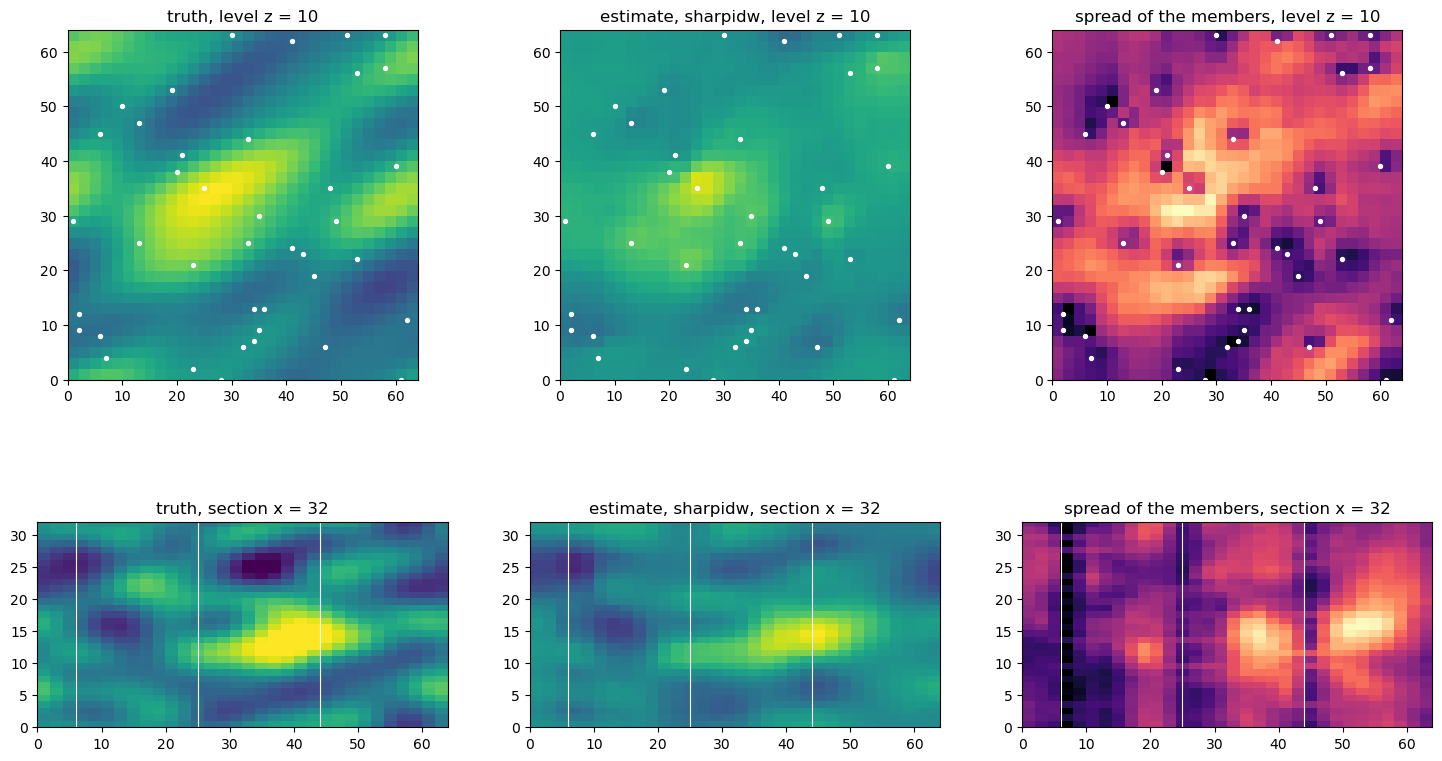

In [3]:
best = min(rows, key=lambda d: rows[d]["five-fold MAE"])
result = esi_nongriddata(points, values, nodes, n_partitions=200, seed=0, **recipes[best])
estimate = result.estimation().reshape(truth.shape)
spread = result.esi_samples().std(axis=1).reshape(truth.shape)
level, section = 10, 16                                       # z = 10, and the section at x = 32
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for col, (title, z) in enumerate((("truth", truth), (f"estimate, {best}", estimate), ("spread of the members", spread))):
    cmap = "magma" if col == 2 else "viridis"
    lim = {} if col == 2 else dict(vmin=-2.5, vmax=2.5)
    axes[0, col].imshow(z[:, :, level].T, origin="lower", cmap=cmap, extent=(0, nx, 0, ny), **lim)
    axes[0, col].scatter(wells[:, 0], wells[:, 1], s=8, c="white")
    axes[0, col].set_title(f"{title}, level z = {level}")
    axes[1, col].imshow(z[section, :, :].T, origin="lower", cmap=cmap, extent=(0, ny, 0, nz), aspect=1, **lim)
    near = np.abs(wells[:, 0] - 2 * section) <= 1
    axes[1, col].vlines(wells[near, 1], 0, nz, colors="white", lw=0.8)
    axes[1, col].set_title(f"{title}, section x = {2 * section}")
plt.show()

The level keeps the large body of high values and its direction, smoother than the truth between the
profiles. The section shows the layering, a thin sheet of high values a few levels deep, which the estimate
follows along its length while thinning it. The members agree near the profiles and spread most over
the high body and its edges, where neighbouring profiles disagree.

### The volume in three dimensions

The cube shows the volume whole, its top and two of its sides, where the layering and the body of high
values meet the faces.

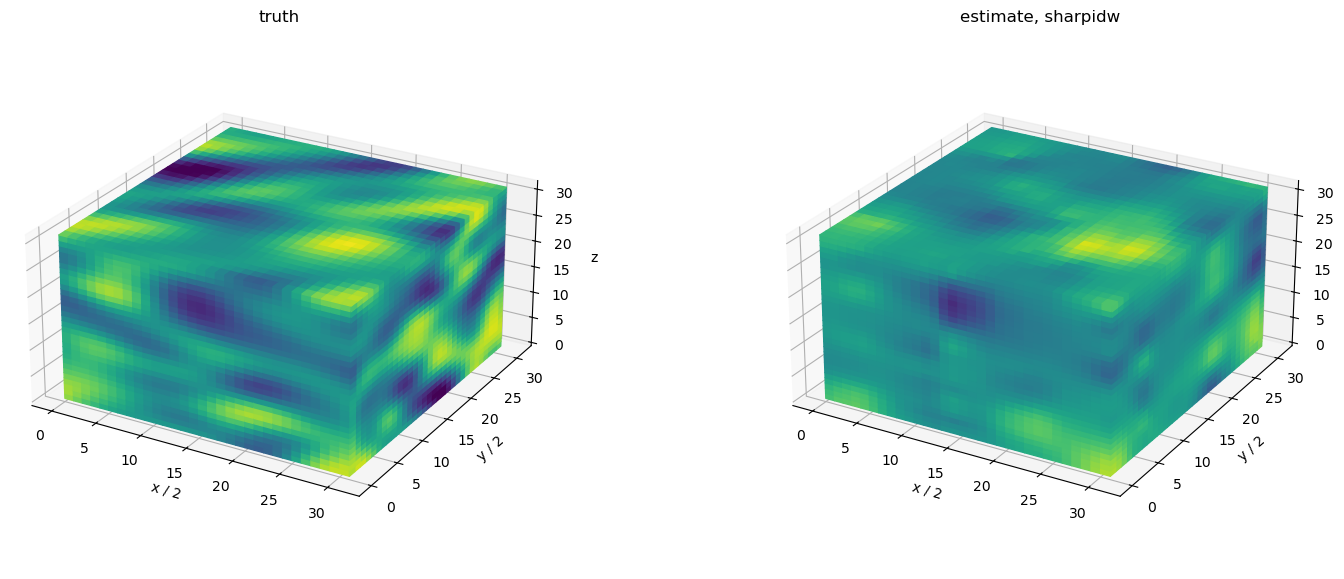

In [4]:
from matplotlib import cm
from matplotlib.colors import Normalize

def cube(ax, volume, title):
    # the faces y = 0, x = max and z = max of a [x, y, z] volume, coloured by its values
    colour = lambda face: cm.viridis(Normalize(-2.5, 2.5)(face))
    sx, sy, sz = volume.shape
    X, Z = np.meshgrid(np.arange(sx), np.arange(sz), indexing="ij")
    ax.plot_surface(X, np.zeros_like(X), Z, facecolors=colour(volume[:, 0, :]), shade=False, rstride=1, cstride=1)
    Y, Z = np.meshgrid(np.arange(sy), np.arange(sz), indexing="ij")
    ax.plot_surface(np.full_like(Y, sx - 1), Y, Z, facecolors=colour(volume[-1, :, :]), shade=False, rstride=1, cstride=1)
    X, Y = np.meshgrid(np.arange(sx), np.arange(sy), indexing="ij")
    ax.plot_surface(X, Y, np.full_like(X, sz - 1), facecolors=colour(volume[:, :, -1]), shade=False, rstride=1, cstride=1)
    ax.set_box_aspect((2 * sx, 2 * sy, sz)); ax.view_init(elev=25, azim=-60)      # x and y every second node
    ax.set_xlabel("x / 2"); ax.set_ylabel("y / 2"); ax.set_zlabel("z"); ax.set_title(title)

fig = plt.figure(figsize=(18, 7))
for k, (title, volume) in enumerate((("truth", truth), (f"estimate, {best}", estimate))):
    cube(fig.add_subplot(1, 2, k + 1, projection="3d"), volume, title)
plt.show()

The truth's faces show the flat layers, each a few levels deep, and the body of high values across
them on the top face. The estimate keeps the main bodies where they reach the faces and their direction
across the map, with softer contrast, as an average over partitions does, most of all on the far faces,
which the profiles reach least.

### Data along boreholes

The bundled data set `load_drill_holes_andes_3D` holds 2 376 samples along boreholes, with a copper
content at each, and 72 529 blocks of a model of the volume to estimate. It has no truth, so the
cross-validated error of the search is the only measure. We choose between the two adaptive decoders,
with 50 partitions per candidate to keep the search short, and estimate the blocks of one level and of
one vertical section, the ones the figure draws.

In [5]:
holes, blocks = load_drill_holes_andes_3D()
hp, hv = holes[["x", "y", "z"]].values, holes["cu"].values
bp = blocks[["x", "y", "z"]].values
print(f"extent of the data: {np.ptp(hp, axis=0).round(0)}, {len(hv)} samples, {len(bp)} blocks")
rows3, recipes3 = {}, {}
for decoder in ("adaptiveidw", "sharpidw"):
    start = time.perf_counter()
    knee = esi_pareto_hparams_search(hp, hv, local_interpolator=decoder, n_partitions=[50],
                                     alpha=[0.9, 0.95, 0.98], k=5, scoring=sf.mae, seed=0).best_result(strategy="knee")
    recipes3[decoder] = dict(local_interpolator=decoder, alpha=knee["alpha"])
    rows3[decoder] = {"alpha": knee["alpha"], "five-fold MAE": knee["decoder_error"], "seconds, search": time.perf_counter() - start}
best3 = min(rows3, key=lambda d: rows3[d]["five-fold MAE"])
z_levels, x_levels = np.unique(bp[:, 2]), np.unique(bp[:, 0])
level_z, x_mid = z_levels[len(z_levels) // 2], x_levels[len(x_levels) // 2]
shown = (bp[:, 2] == level_z) | (bp[:, 0] == x_mid)
start = time.perf_counter()
cu = esi_nongriddata(hp, hv, bp[shown], n_partitions=200, seed=0, **recipes3[best3]).estimation()
seconds = time.perf_counter() - start
print(f"{shown.sum()} of {len(bp)} blocks in {seconds:.1f} s with 200 partitions")
pd.DataFrame(rows3).T.round(4)

extent of the data: [399. 597. 130.], 2376 samples, 72529 blocks
4209 of 72529 blocks in 30.3 s with 200 partitions


,alpha,five-fold MAE,"seconds, search"
adaptiveidw,0.95,0.2468,43.6897
sharpidw,0.95,0.2486,49.8643


The two adaptive decoders come within a hundredth of each other, the adaptive IDW slightly ahead by
cross-validation at the same granularity. The 4 209 blocks of the level and the section take under a
minute with 200 partitions, so the whole model of 72 529 blocks would take some fifteen minutes on this
machine. Each search takes about a minute.

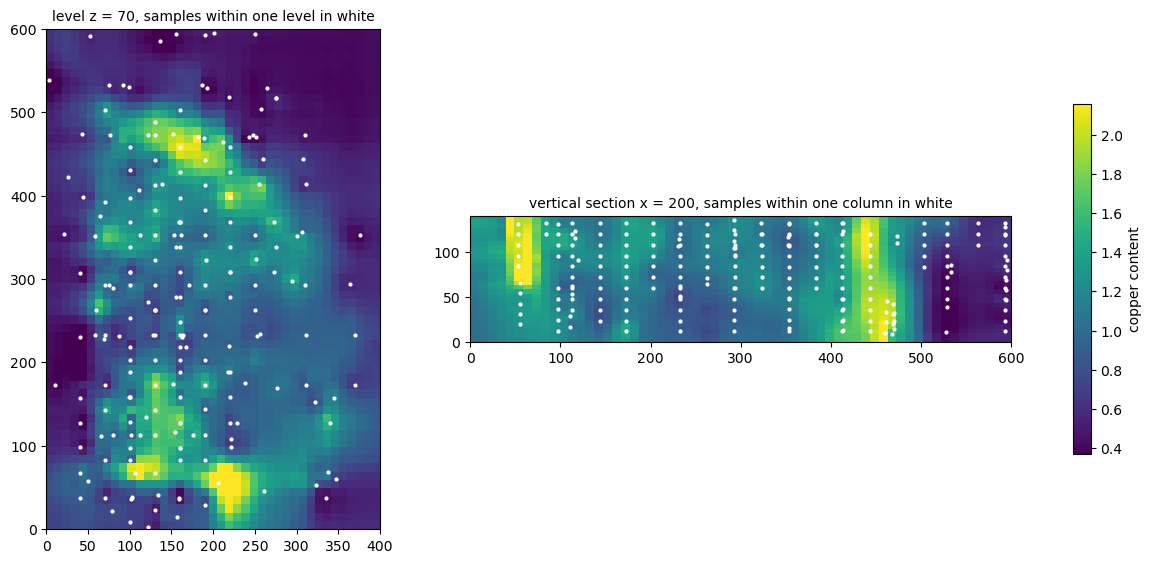

In [6]:
def as_image(a, b, values):
    # blocks on a regular grid of (a, b) coordinates as an image, NaN where no block lies
    ua, ub = np.unique(a), np.unique(b)
    image = np.full((len(ua), len(ub)), np.nan)
    image[np.searchsorted(ua, a), np.searchsorted(ub, b)] = values
    return image, (ua[0], ua[-1], ub[0], ub[-1])

sp = bp[shown]
on_level, on_section = sp[:, 2] == level_z, sp[:, 0] == x_mid
lo, hi = np.nanpercentile(cu, [1, 99])
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw=dict(width_ratios=[1, 1.5]))
image, extent = as_image(sp[on_level, 0], sp[on_level, 1], cu[on_level])
im = axes[0].imshow(image.T, origin="lower", extent=extent, cmap="viridis", vmin=lo, vmax=hi)
near_level = np.abs(hp[:, 2] - level_z) < np.diff(z_levels).min()
axes[0].scatter(hp[near_level, 0], hp[near_level, 1], s=4, c="white")
axes[0].set_title(f"level z = {level_z:.0f}, samples within one level in white", fontsize=10)
image, extent = as_image(sp[on_section, 1], sp[on_section, 2], cu[on_section])
axes[1].imshow(image.T, origin="lower", extent=extent, cmap="viridis", vmin=lo, vmax=hi)
near_section = np.abs(hp[:, 0] - x_mid) < np.diff(x_levels).min()
axes[1].scatter(hp[near_section, 1], hp[near_section, 2], s=4, c="white")
axes[1].set_title(f"vertical section x = {x_mid:.0f}, samples within one column in white", fontsize=10)
fig.colorbar(im, ax=axes, shrink=0.7, label="copper content")
plt.show()

The level shows a band of higher copper content running north to south through the middle of the
boreholes, highest near its southern end and again in the north, with low values on the east and west
edges, where the boreholes thin out. The section crosses two columns of high content near y = 60 and
y = 440, each following a line of samples from top to bottom, while the content falls to the south-east
of the second.

## Pitfalls

- **An isotropic decoder on a layered volume.** Plain IDW weighs a datum in depth like one across the
  map at the same distance. Use the adaptive decoders, which fit the anisotropy in each cell.
- **Coordinates in different units.** Depth in metres and position in kilometres make one axis look a
  thousand times longer. The partitions cut each axis in proportion to its side, so put all axes in one
  unit before running.
- **A spread read as an error.** The members' spread grows away from the profiles, where the partitions
  disagree, without measuring how wrong the estimate is there.
- **Time.** The cost grows with the number of nodes and partitions. Estimate on a coarser grid while
  choosing, then on the full one.

## Try it yourself

1. Sample the layered field along 20 profiles, half as many, and compare the decoders.
2. Use Voronoi partitions (`p_process="voronoi"`) in three dimensions.
3. Estimate the copper content with a drawing decoder (`"wdraw_sharpidw"`) and map the probability of
   exceeding the median.

## Next

- *The decoders*, for the adaptive and sharpened IDW.
- *How many partitions?*, for the number a volume needs.
- *Estimating categories*, for categories in three dimensions.
- The documentation's [Decoders](https://spatialize.readthedocs.io/en/latest/theory/decoders.html)
  (theory).